# MovieLens 1M: исследовательский анализ данных

Исследование состава данных, распределения оценок и активности пользователей.
Отдельно рассматривается временное разделение для рекомендательной системы.

Положительный отклик — оценка **4–5**. Все даты приведены в **UTC**.
Полный набор данных используется для описательного анализа; при обучении моделей
история и признаки ограничиваются датой рекомендации.

## 1. Загрузка данных

MovieLens 1M состоит из трёх таблиц: оценки, описания фильмов и профили пользователей.
Общая функция загрузки читает исходные файлы; дальнейшие расчёты выполняются в этом ноутбуке.

In [1]:
from pathlib import Path
from math import ceil
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent / "movielens-reccomender"
elif (ROOT / "movielens-reccomender").exists():
    ROOT = ROOT / "movielens-reccomender"
elif not (ROOT / "configs/experiment.json").exists():
    ROOT = ROOT / "ml-1m/movielens-reccomender"

sys.path.insert(0, str(ROOT / "src"))
from movielens_recsys.data import load_movielens

config = json.loads((ROOT / "configs/experiment.json").read_text(encoding="utf-8"))
ratings, movies, users = load_movielens(ROOT / config["data_dir"])
positive_threshold = config["positive_threshold"]

In [2]:
display(ratings.head())
display(movies.head())
display(users.head())

,user_id,movie_id,rating,timestamp,datetime
0,1,1193,5,978300760,2000-12-31 22:12:40+00:00
1,1,661,3,978302109,2000-12-31 22:35:09+00:00
2,1,914,3,978301968,2000-12-31 22:32:48+00:00
3,1,3408,4,978300275,2000-12-31 22:04:35+00:00
4,1,2355,5,978824291,2001-01-06 23:38:11+00:00


,movie_id,title,genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy


,user_id,gender,age,occupation,zip_code
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117
3,4,M,45,7,02460
4,5,M,25,20,55455


## 2. Размер и состав набора данных

Число фильмов в каталоге и число фильмов с оценками различаются.
Для совместной фильтрации важны именно фильмы, для которых уже есть взаимодействия.

In [3]:
unrated_movies = movies[~movies["movie_id"].isin(ratings["movie_id"])]

dataset_summary = pd.Series({
    "Оценок": len(ratings),
    "Пользователей": ratings["user_id"].nunique(),
    "Фильмов с оценками": ratings["movie_id"].nunique(),
    "Фильмов в каталоге": len(movies),
    "Фильмов без оценок": len(unrated_movies),
    "Первая оценка": ratings["datetime"].min(),
    "Последняя оценка": ratings["datetime"].max(),
}, name="Значение")

display(dataset_summary.to_frame())

,Значение
Оценок,1000209
Пользователей,6040
Фильмов с оценками,3706
Фильмов в каталоге,3883
Фильмов без оценок,177
Первая оценка,2000-04-25 23:05:32+00:00
Последняя оценка,2003-02-28 17:49:50+00:00


В наборе **1 000 209 оценок**, **6 040 пользователей** и **3 706 оценённых фильмов**.
В каталоге есть ещё **177 фильмов без оценок**. Само наличие фильма в каталоге
не даёт ALS или ItemKNN данных для изучения его предпочтений.

## 3. Проверка качества данных

Проверяются пропуски, дубликаты, диапазон оценок и соответствие идентификаторов
между таблицами. Повтор пары пользователь–фильм мог бы привести к повторному
учёту одного взаимодействия при расчёте популярности или заполнении матрицы.

In [4]:
checks = pd.Series({
    "Пропуски в оценках": ratings.isna().sum().sum(),
    "Пропуски в фильмах": movies.isna().sum().sum(),
    "Пропуски в пользователях": users.isna().sum().sum(),
    "Повторы пар пользователь–фильм": ratings.duplicated(["user_id", "movie_id"]).sum(),
    "Повторы идентификаторов фильмов": movies["movie_id"].duplicated().sum(),
    "Повторы идентификаторов пользователей": users["user_id"].duplicated().sum(),
    "Оценки неизвестных пользователей": (~ratings["user_id"].isin(users["user_id"])).sum(),
    "Оценки неизвестных фильмов": (~ratings["movie_id"].isin(movies["movie_id"])).sum(),
    "Оценки вне диапазона 1–5": (~ratings["rating"].between(1, 5)).sum(),
}, name="Число нарушений")

display(checks.to_frame())

,Число нарушений
Пропуски в оценках,0
Пропуски в фильмах,0
Пропуски в пользователях,0
Повторы пар пользователь–фильм,0
Повторы идентификаторов фильмов,0
Повторы идентификаторов пользователей,0
Оценки неизвестных пользователей,0
Оценки неизвестных фильмов,0
Оценки вне диапазона 1–5,0


Все перечисленные проверки дали нулевые значения. Для этих проверок исправление
пропусков или удаление дубликатов не требуется.

## 4. Распределение оценок

В проекте оценки 4–5 считаются положительными взаимодействиями.
Оценки 1–3 остаются в полной истории пользователя и исключаются из повторных рекомендаций.
Отсутствие оценки не означает, что фильм пользователю не понравился.

,Число оценок,"Доля, %"
rating,,
1,56174,5.62
2,107557,10.75
3,261197,26.11
4,348971,34.89
5,226310,22.63


Положительных оценок: 57.52%
Пользователей без положительных оценок: 2


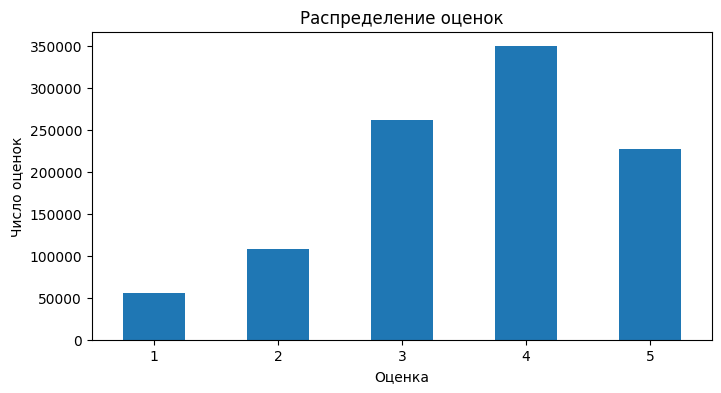

In [5]:
rating_counts = ratings["rating"].value_counts().sort_index()
positive_history = ratings[ratings["rating"] >= positive_threshold]
positive_fraction = len(positive_history) / len(ratings)
users_without_positives = (~users["user_id"].isin(positive_history["user_id"])).sum()

display(pd.DataFrame({
    "Число оценок": rating_counts,
    "Доля, %": (rating_counts / len(ratings) * 100).round(2),
}))
print(f"Положительных оценок: {positive_fraction:.2%}")
print("Пользователей без положительных оценок:", users_without_positives)

fig, ax = plt.subplots(figsize=(8, 4))
rating_counts.plot.bar(ax=ax, rot=0)
ax.set(title="Распределение оценок", xlabel="Оценка", ylabel="Число оценок")
plt.show()

Положительные оценки составляют **57,52%** всех взаимодействий.
При обучении implicit ALS они преобразуются в единицы в матрице пользователь–фильм.
Полная история с любыми оценками используется отдельно для фильтрации просмотренных фильмов.

## 5. Активность пользователей и разреженность

Количество оценок различается между пользователями и фильмами.
Логарифмическая шкала по вертикали помогает увидеть редкие случаи с очень высокой активностью.
Заполненность матрицы рассчитывается по всем оценкам для пользователей и оценённых фильмов.

,Оценок на пользователя,Оценок на фильм
count,6040.00,3706.00
mean,165.60,269.89
std,192.75,384.05
min,20.00,1.00
25%,44.00,33.00
50%,96.00,123.50
75%,208.00,350.00
90%,400.00,729.50
99%,906.66,1784.90
max,2314.00,3428.00


Заполненность матрицы: 4.47%
Доля оценок у 1% наиболее часто оцениваемых фильмов: 8.91%


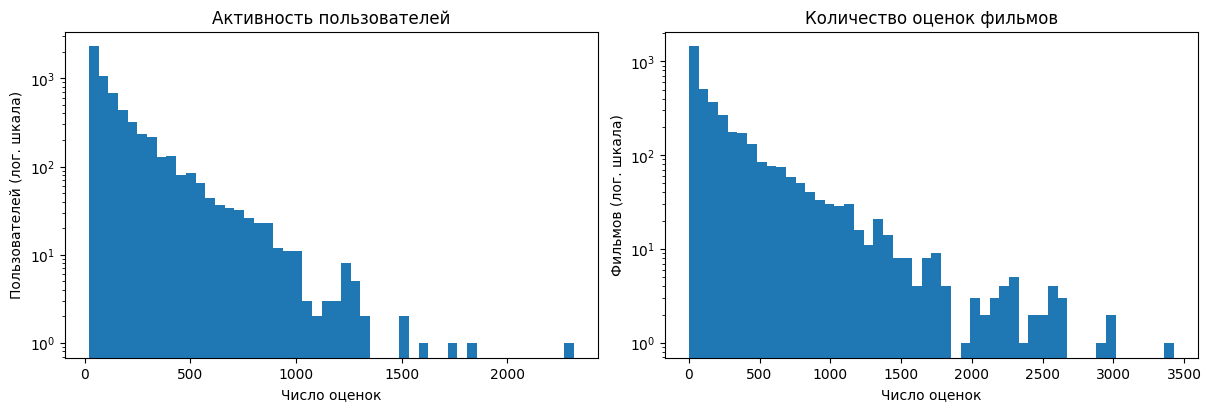

In [6]:
per_user = ratings.groupby("user_id").size()
per_movie = ratings.groupby("movie_id").size()

activity_summary = pd.DataFrame({
    "Оценок на пользователя": per_user.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]),
    "Оценок на фильм": per_movie.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]),
})
display(activity_summary.round(2))

density = len(ratings) / (len(per_user) * len(per_movie))
top_movie_count = ceil(len(per_movie) * 0.01)
top_movie_share = per_movie.nlargest(top_movie_count).sum() / len(ratings)
print(f"Заполненность матрицы: {density:.2%}")
print(f"Доля оценок у 1% наиболее часто оцениваемых фильмов: {top_movie_share:.2%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].hist(per_user, bins=50, log=True)
axes[0].set(title="Активность пользователей", xlabel="Число оценок", ylabel="Пользователей (лог. шкала)")
axes[1].hist(per_movie, bins=50, log=True)
axes[1].set(title="Количество оценок фильмов", xlabel="Число оценок", ylabel="Фильмов (лог. шкала)")
plt.show()

Медианное число оценок — **96 на пользователя** и **123,5 на фильм**.
Матрица заполнена примерно на **4,47%**: большая часть пар пользователь–фильм не наблюдалась.
На 1% наиболее часто оцениваемых фильмов приходится **8,91%** оценок.
MostPopular служит отправной точкой для проверки того, что дают персональные модели сверх общей популярности.

## 6. Активность по месяцам

Число оценок по месяцам показывает, насколько равномерно события распределены во времени.
Для временного разделения это важнее случайного перемешивания строк.

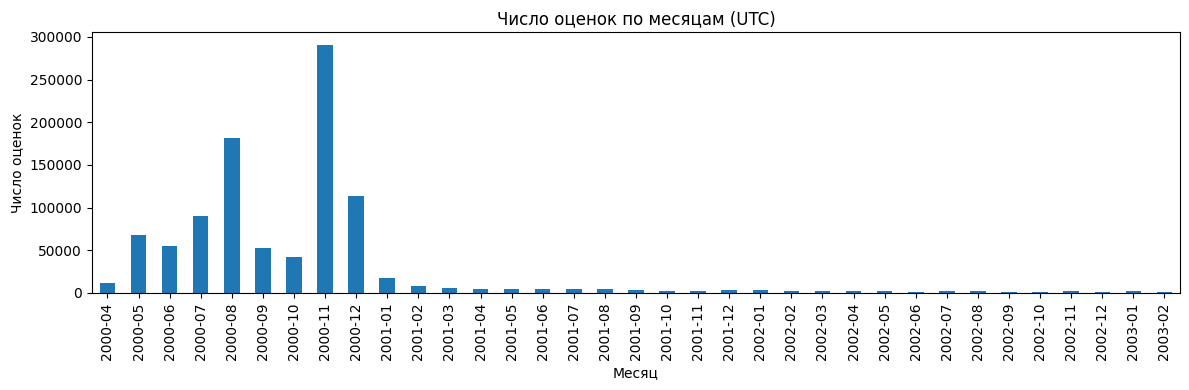

In [7]:
monthly = ratings.assign(month=ratings["datetime"].dt.strftime("%Y-%m")).groupby("month").agg(
    events=("rating", "size"),
    users=("user_id", "nunique"),
    mean_rating=("rating", "mean"),
)

fig, ax = plt.subplots(figsize=(12, 4))
monthly["events"].plot.bar(ax=ax, rot=90)
ax.set(title="Число оценок по месяцам (UTC)", xlabel="Месяц", ylabel="Число оценок")
plt.tight_layout()
plt.show()

Оценки охватывают период с апреля 2000 года по февраль 2003 года и распределены неравномерно.
В эксперименте CatBoost обучается на ответах сентября–декабря 2000 года,
январь 2001 года используется для выбора модели, февраль — для итоговой оценки.
Более ранние оценки входят в историю каждого соответствующего месяца.

## 7. За какой срок пользователь выставил свои оценки

Для каждого пользователя рассчитывается время между первой и последней оценками.
Короткий интервал может означать, что человек за один сеанс оценивал фильмы,
просмотренные в разное время. Временная метка относится к выставлению оценки.

,Доля пользователей
"Все оценки в пределах суток, %",62.93
"Все оценки в пределах недели, %",70.25


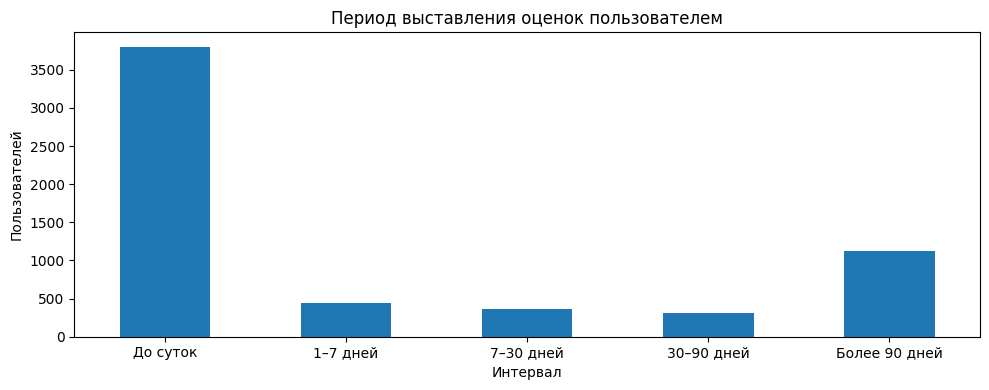

In [8]:
user_dates = ratings.groupby("user_id")["datetime"].agg(["min", "max"])
span_days = (user_dates["max"] - user_dates["min"]) / pd.Timedelta(days=1)

span_summary = pd.Series({
    "Все оценки в пределах суток, %": (span_days <= 1).mean() * 100,
    "Все оценки в пределах недели, %": (span_days <= 7).mean() * 100,
}, name="Доля пользователей")
display(span_summary.round(2).to_frame())

span_groups = pd.cut(
    span_days,
    bins=[0, 1, 7, 30, 90, float("inf")],
    labels=["До суток", "1–7 дней", "7–30 дней", "30–90 дней", "Более 90 дней"],
    include_lowest=True,
)
fig, ax = plt.subplots(figsize=(10, 4))
span_groups.value_counts(sort=False).plot.bar(ax=ax, rot=0)
ax.set(title="Период выставления оценок пользователем", xlabel="Интервал", ylabel="Пользователей")
plt.tight_layout()
plt.show()

У **62,93% пользователей** все оценки укладываются в сутки, у **70,25%** — в неделю.
Поэтому календарное разделение может оставлять много пользователей без истории до начала месяца.
В проекте основные метрики рассчитываются для пользователей с прошлой историей
и хотя бы одной положительной оценкой в целевом месяце. Эти результаты относятся к такой группе пользователей.

## 8. Жанры в каталоге

У одного фильма может быть несколько жанров, поэтому число упоминаний жанров
в сумме больше числа фильмов. Здесь описывается состав каталога без учёта числа оценок.

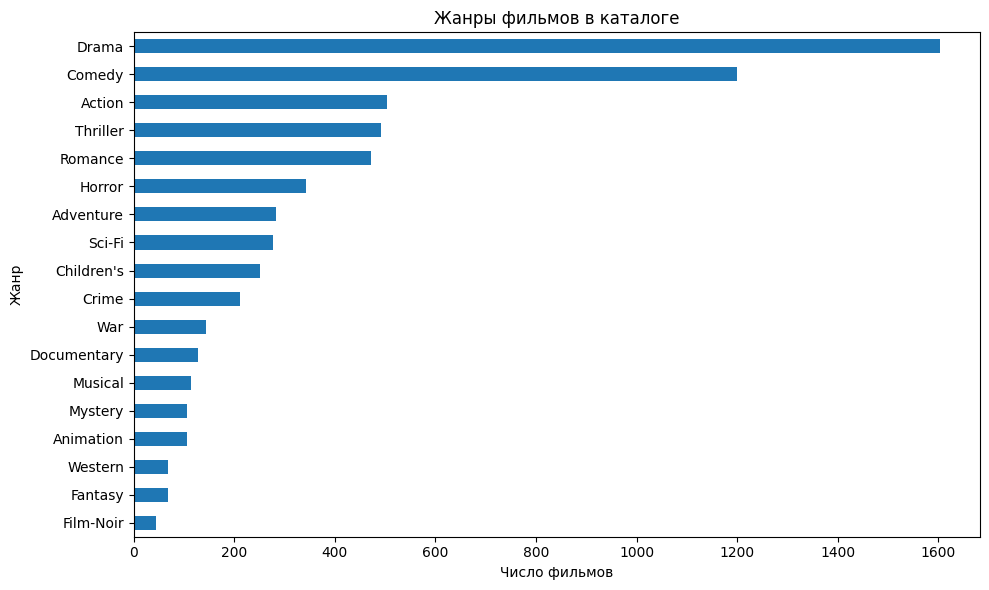

In [9]:
genre_counts = movies["genres"].str.split("|").explode().value_counts()

fig, ax = plt.subplots(figsize=(10, 6))
genre_counts.sort_values().plot.barh(ax=ax)
ax.set(title="Жанры фильмов в каталоге", xlabel="Число фильмов", ylabel="Жанр")
plt.tight_layout()
plt.show()

## 9. Проверка календарных окон

Для каждого месяца история содержит только оценки, поставленные **до его начала**.
Пользователь и фильм считаются известными, если уже встречались в этой истории с любой оценкой.

Последний столбец показывает, какая доля положительных оценок целевого месяца
относится к известным пользователям и известным фильмам. Полнота подбора кандидатов
оценивается отдельно: для неё нужны рекомендации обученной модели.

Проверка начинается с июня, чтобы увидеть ранние окна. Обучающие месяцы CatBoost
при этом остаются прежними: сентябрь–декабрь.

In [10]:
month_starts = pd.date_range("2000-06-01", "2001-03-01", freq="MS", tz="UTC")
window_rows = []

for start, end in zip(month_starts[:-1], month_starts[1:]):
    history = ratings[ratings["datetime"] < start]
    target = ratings[(ratings["datetime"] >= start) & (ratings["datetime"] < end)]
    positives = target[target["rating"] >= positive_threshold]

    known_users = set(history["user_id"])
    known_movies = set(history["movie_id"])
    known_user = positives["user_id"].isin(known_users)
    known_movie = positives["movie_id"].isin(known_movies)

    window_rows.append({
        "Начало месяца": start.strftime("%Y-%m-%d"),
        "Оценок в истории": len(history),
        "Оценок за месяц": len(target),
        "Пользователей с положительными оценками": positives["user_id"].nunique(),
        "Из них с историей": positives.loc[known_user, "user_id"].nunique(),
        "Доля известных пар, %": (known_user & known_movie).mean() * 100,
    })

windows = pd.DataFrame(window_rows)
display(windows.round(2))

,Начало месяца,Оценок в истории,Оценок за месяц,Пользователей с положительными оценками,Из них с историей,"Доля известных пар, %"
0,2000-06-01,78833,54486,506,99,8.20
1,2000-07-01,133319,90334,769,137,6.72
2,2000-08-01,223653,182109,1287,188,4.71
3,2000-09-01,405762,52421,559,242,16.57
4,2000-10-01,458183,42294,486,238,19.14
5,2000-11-01,500477,290793,2334,229,1.96
6,2000-12-01,791270,113487,1207,538,23.38
7,2001-01-01,904757,18004,506,506,99.98
8,2001-02-01,922761,8136,348,347,98.56


В январе у всех **506** пользователей с положительными оценками есть прошлая история.
В феврале история есть у **347 из 348** таких пользователей.
В ранних окнах доля пользователей с историей заметно ниже.

Доступность фильма приближённо определяется по его первому появлению в истории оценок:
в MovieLens нет дат добавления фильмов в каталог.

## 10. Временное разделение эксперимента

| Этап | История для retrieval и признаков | Месяц правильных ответов |
| --- | --- | --- |
| Обучение CatBoost | Строго до начала каждого месяца | Сентябрь–декабрь 2000 |
| Валидация и подбор параметров | До 1 января 2001 | Январь 2001 |
| Финальная оценка | До 1 февраля 2001 | Февраль 2001 |

В каждом обучающем месяце ALS и ItemKNN заново обучаются на его прошлом.
Правильные ответы включают все положительно оценённые фильмы целевого месяца,
в том числе пропущенные подбором кандидатов.

Февраль уже просматривался до дополнительного подбора параметров;
повторная оценка сохраняет это ограничение эксперимента.

## Основные выводы

- Проверки пропусков, дубликатов и связей между таблицами не выявили нарушений.
- У большинства пользователей оценки сосредоточены на коротком промежутке времени;
  временная оценка зависит от выбранной группы пользователей.
- Популярность, сходство фильмов и признаки ранжирования рассчитываются только по истории до даты рекомендации.
- Ограничения временных меток и выбранной группы пользователей учитываются при интерпретации метрик.

Архитектура и результаты модели описаны в [README проекта](../movielens-reccomender/README.md).